In [72]:
#elliot
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

from ipywidgets import interact
import ipywidgets as widgets
from IPython.display import display

In [110]:
df = pd.read_csv('Crimes_-_2001_to_Present_20261110.csv')
# df['Date'] = pd.to_datetime(df['Date'], format='%m/%d/%Y %I:%M:%S %p').dt.date 
# above line conv to date timer
df['Date'] = df['Date'].str[:10]
#just conv to string, makes later analysis more difficult, will have to truncate again, or make new col 'month', based on the truncated value of the first col
display(df.head())
display(df.describe())
display(df.info())



,Date,Block,Primary Type,Description,Location Description,Arrest,Domestic,District,FBI Code,X Coordinate,Y Coordinate,Year,Latitude,Longitude,ID,Updated On
0,11/02/2026,050XX W SCHUBERT AVE,DECEPTIVE PRACTICE,ILLEGAL USE CASH CARD,OTHER (SPECIFY),False,False,25,11,1142302.0,1917487.0,2026,41.929643,-87.752500,14379234,11/09/2026 03:55:38 PM
1,11/02/2026,0000X W 111TH PL,MOTOR VEHICLE THEFT,AUTOMOBILE,RESIDENCE,False,False,5,07,1178013.0,1831034.0,2026,41.691669,-87.623895,14379045,11/09/2026 03:55:38 PM
2,11/02/2026,020XX N MILWAUKEE AVE,THEFT,RETAIL THEFT,SMALL RETAIL STORE,False,False,14,06,1159682.0,1913243.0,2026,41.917656,-87.688750,14377662,11/09/2026 03:55:38 PM
3,11/02/2026,026XX E 73RD ST,DECEPTIVE PRACTICE,ILLEGAL USE CASH CARD,STREET,False,False,3,11,1195178.0,1857641.0,2026,41.764276,-87.560178,14377568,11/09/2026 03:55:38 PM
4,11/02/2026,001XX W ADAMS ST,THEFT,OVER $500,STREET,False,False,1,06,1175062.0,1899421.0,2026,41.879397,-87.632659,14378355,11/09/2026 03:55:38 PM


,District,X Coordinate,Y Coordinate,Year,Latitude,Longitude,ID
count,1.883349e+06,1.854733e+06,1.854733e+06,1.883349e+06,1.854733e+06,1.854733e+06,1.883349e+06
mean,1.132279e+01,1.165298e+06,1.886755e+06,2.022457e+03,4.184484e+01,-8.766891e+01,1.293435e+07
std,7.255089e+00,1.638866e+04,3.171936e+04,2.258854e+00,8.723324e-02,5.963103e-02,1.043005e+06
min,1.000000e+00,0.000000e+00,0.000000e+00,2.019000e+03,3.661945e+01,-9.168657e+01,2.436800e+04
25%,5.000000e+00,1.153799e+06,1.859349e+06,2.020000e+03,4.176937e+01,-8.771077e+01,1.225658e+07
50%,1.000000e+01,1.167135e+06,1.893147e+06,2.023000e+03,4.186249e+01,-8.766208e+01,1.297098e+07
75%,1.700000e+01,1.176764e+06,1.909714e+06,2.024000e+03,4.190814e+01,-8.762693e+01,1.366239e+07
max,6.100000e+01,1.205119e+06,1.951527e+06,2.026000e+03,4.202259e+01,-8.752453e+01,1.438472e+07


<class 'pandas.DataFrame'>
RangeIndex: 1883349 entries, 0 to 1883348
Data columns (total 16 columns):
 #   Column                Dtype  
---  ------                -----  
 0   Date                  str    
 1   Block                 str    
 2   Primary Type          str    
 3   Description           str    
 4   Location Description  str    
 5   Arrest                bool   
 6   Domestic              bool   
 7   District              int64  
 8   FBI Code              str    
 9   X Coordinate          float64
 10  Y Coordinate          float64
 11  Year                  int64  
 12  Latitude              float64
 13  Longitude             float64
 14  ID                    int64  
 15  Updated On            str    
dtypes: bool(2), float64(4), int64(3), str(7)
memory usage: 204.8 MB


None

In [74]:
#filter top categories
df['crimecol'] = df['Primary Type'].astype("category")
top_categories = df['Primary Type'].value_counts().nlargest(10).index
df.loc[~df['Primary Type'].isin(top_categories), "crimecol"] = "OTHER OFFENSE"
df.loc[df['Primary Type'].isin(top_categories), "crimecol"] = df['Primary Type']
display(df.head())
display(df.info())


,Date,Block,Primary Type,Description,Location Description,Arrest,Domestic,District,FBI Code,X Coordinate,Y Coordinate,Year,Latitude,Longitude,ID,Updated On,crimecol
0,11/02/2026,050XX W SCHUBERT AVE,DECEPTIVE PRACTICE,ILLEGAL USE CASH CARD,OTHER (SPECIFY),False,False,25,11,1142302.0,1917487.0,2026,41.929643,-87.752500,14379234,11/09/2026 03:55:38 PM,DECEPTIVE PRACTICE
1,11/02/2026,0000X W 111TH PL,MOTOR VEHICLE THEFT,AUTOMOBILE,RESIDENCE,False,False,5,07,1178013.0,1831034.0,2026,41.691669,-87.623895,14379045,11/09/2026 03:55:38 PM,MOTOR VEHICLE THEFT
2,11/02/2026,020XX N MILWAUKEE AVE,THEFT,RETAIL THEFT,SMALL RETAIL STORE,False,False,14,06,1159682.0,1913243.0,2026,41.917656,-87.688750,14377662,11/09/2026 03:55:38 PM,THEFT
3,11/02/2026,026XX E 73RD ST,DECEPTIVE PRACTICE,ILLEGAL USE CASH CARD,STREET,False,False,3,11,1195178.0,1857641.0,2026,41.764276,-87.560178,14377568,11/09/2026 03:55:38 PM,DECEPTIVE PRACTICE
4,11/02/2026,001XX W ADAMS ST,THEFT,OVER $500,STREET,False,False,1,06,1175062.0,1899421.0,2026,41.879397,-87.632659,14378355,11/09/2026 03:55:38 PM,THEFT


<class 'pandas.DataFrame'>
RangeIndex: 1883349 entries, 0 to 1883348
Data columns (total 17 columns):
 #   Column                Dtype   
---  ------                -----   
 0   Date                  str     
 1   Block                 str     
 2   Primary Type          str     
 3   Description           str     
 4   Location Description  str     
 5   Arrest                bool    
 6   Domestic              bool    
 7   District              int64   
 8   FBI Code              str     
 9   X Coordinate          float64 
 10  Y Coordinate          float64 
 11  Year                  int64   
 12  Latitude              float64 
 13  Longitude             float64 
 14  ID                    int64   
 15  Updated On            str     
 16  crimecol              category
dtypes: bool(2), category(1), float64(4), int64(3), str(7)
memory usage: 206.6 MB


None

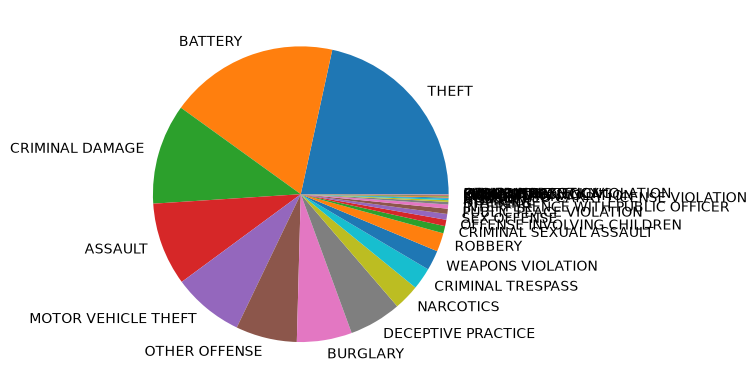

In [75]:
#interactive pie chart
df2 = df.query("Year > 2025")
df2['Primary Type'].value_counts().plot.pie()
plt.show()

In [76]:
@interact(year=[2023,2024,2025,2026],n=[1,2,3,4,5,6,7,8,9,10,11,12,13,14])
def pieplotcrimes(year=2026, n=8):
    pietempdf = df.query("Year == @year")
    pietempdf['Primary Type'].value_counts().head(n).plot.pie(autopct='%1.2f%%', cmap='RdPu')
#how to make this better?, could make more interactive idk


interactive(children=(Dropdown(description='year', index=3, options=(2023, 2024, 2025, 2026), value=2026), Dro…

In [77]:
@interact( crime = ['THEFT', 'BATTERY', 'CRIMINAL DAMAGE', 'ASSAULT', 'MOTOR VEHICLE THEFT',
       'OTHER OFFENSE', 'DECEPTIVE PRACTICE', 'BURGLARY', 'ROBBERY','WEAPONS VIOLATION'])
def pieplotcrimes(crime='THEFT', n=8):
    tempdf = df.query("crimecol == @crime")
    tempdf['Description'].value_counts().head(n).plot.pie(autopct='%1.2f%%', cmap='RdPu')
#how to make this better?, could make more interactive idk


interactive(children=(Dropdown(description='crime', options=('THEFT', 'BATTERY', 'CRIMINAL DAMAGE', 'ASSAULT',…

In [78]:
@interact(year=[2023, 2024, 2025, 2026])
def alluvialplot(year=2026):
    alluvialtempdf = df.query("Year == @year").copy()
    alluvialtempdf['ArrestNum'] = alluvialtempdf['Arrest'].astype(int)
        #alluvialtempf = df[df['Year']==year]

    fig = px.parallel_categories(
        alluvialtempdf,
        dimensions=['crimecol', 'Arrest', 'Domestic'],
        color='ArrestNum',
        color_continuous_scale=['steelblue', 'crimson'],
        width=800, height=450,
    )
    fig.update_traces(line_shape='hspline')
    fig.update_layout(coloraxis_showscale=False)
    fig.show()

interactive(children=(Dropdown(description='year', index=3, options=(2023, 2024, 2025, 2026), value=2026), Out…

make everything interactive, pie chart first, then alluvial, and then the scatterplot, and idk wtf to do for the holiday, could do the distributoin of the crimes per month, like a corr matrix or something

Import interactive package

do the fricking alluvial, except use description and location again, then fix up the stuff for the presentation

In [79]:
@interact( crime = ['THEFT', 'BATTERY', 'CRIMINAL DAMAGE', 'ASSAULT', 'MOTOR VEHICLE THEFT',
       'OTHER OFFENSE', 'DECEPTIVE PRACTICE', 'BURGLARY', 'ROBBERY','WEAPONS VIOLATION'])
def alluvialplot(crime='THEFT'):
    alluvialdf = df.query("crimecol == @crime").copy()

    fig = px.parallel_categories(
        alluvialdf,
        dimensions=['crimecol', 'Description'],
        width=800, height=450,
    )
    fig.update_traces(line_shape='hspline')
    fig.update_layout(coloraxis_showscale=False)
    fig.show()
#this one is really rought, idk how to use it
#instead of an alluvial, could switch to another pie plot

interactive(children=(Dropdown(description='crime', options=('THEFT', 'BATTERY', 'CRIMINAL DAMAGE', 'ASSAULT',…

In [80]:
#should this be interactive based on amount of crimes too? like the pie plot?
#to show the domestic arrest rate, would have to filer and show another boxplot where out of the arrests, for a crime the amount that are domestic
@interact(year=[2023,2024,2025,2026])

def barplot(year=2023):
    barplotdf = df.query("Year == @year").copy()
    g = (barplotdf.groupby('Primary Type')['Arrest']
            .agg(total='size', arrests='sum')
            .query('total >= 500')
    )
#g = g.sort_values('total')
    g['rate'] = g['arrests'] / g['total']
    g = g.sort_values('rate')
    g['total'].plot.barh(color='steelblue', figsize=(8, 8), label='Total incidents')
    g['arrests'].plot.barh(color='crimson', label='Arrests')
    plt.xlabel('Number of incidents')
    plt.legend()
    plt.show()

interactive(children=(Dropdown(description='year', options=(2023, 2024, 2025, 2026), value=2023), Output()), _…

In [81]:
#hexbin interactive 
#make this interactve on type of crime as well
@interact(year=[2023,2024,2025,2026], crime = ['THEFT', 'BATTERY', 'CRIMINAL DAMAGE', 'ASSAULT', 'MOTOR VEHICLE THEFT',
       'OTHER OFFENSE', 'DECEPTIVE PRACTICE', 'BURGLARY', 'ROBBERY','WEAPONS VIOLATION'])
def hexbinplot(year=2023, crime = "THEFT"):
    hexbindf = df.query("Year == @year and crimecol == @crime")
    hexbindf.plot.hexbin('Longitude', 'Latitude',  gridsize=70, cmap="PuRd", figsize=(7, 7), title =  f'Map of {crime} in Chicago in the {year}')
    plt.show()

interactive(children=(Dropdown(description='year', options=(2023, 2024, 2025, 2026), value=2023), Dropdown(des…

In [82]:
#scatterplot interactive
@interact(year=[2023,2024,2025,2026], crime = ['THEFT', 'BATTERY', 'CRIMINAL DAMAGE', 'ASSAULT', 'MOTOR VEHICLE THEFT',
       'OTHER OFFENSE', 'DECEPTIVE PRACTICE', 'BURGLARY', 'ROBBERY','WEAPONS VIOLATION'])
def scatterplot(year=2023, crime = "THEFT"):
    scatterplotdf = df.query("Year == @year and crimecol == @crime")
    scatterplotdf.plot.scatter('Longitude', 'Latitude', s=0.7, alpha=.08, figsize=(7, 7), title = f'Map of {crime} in Chicago in the {year}', color = 'crimson')
    plt.show()

interactive(children=(Dropdown(description='year', options=(2023, 2024, 2025, 2026), value=2023), Dropdown(des…

In [83]:
#make the matrix, just do the month shit
#fuck the years wtih this shit, just do the months years and crime count for a specific crime
df['month'] = df['Date'].str[:2]
df['month'] = df['month'].astype("str")
monthdict = {'01':'January','02':'February', '03':'March', '04':'April', '05':'May','06':'June', '07':'July', '08':'August','09':'September', '10':'October','11':'November','12':'December'}
df['month_name'] = df['month'].map(monthdict)
#use .map, call a dictionary, and replaces all working values with that dictionary, then pivot table and value counts

#think this has to be part of the custom dataframe
@interact(crime = ['THEFT', 'BATTERY', 'CRIMINAL DAMAGE', 'ASSAULT', 'MOTOR VEHICLE THEFT',
                   'OTHER OFFENSE', 'DECEPTIVE PRACTICE', 'BURGLARY', 'ROBBERY','WEAPONS VIOLATION'])
def matrixplot(crime='THEFT'):
    matrixplot = df.query("crimecol == @crime")
    df_wide = matrixplot.pivot_table(index='month_name', columns='Year', values='ID', aggfunc='count')
    df_wide = df_wide.reindex(["January", "February", "March","April","May","June","July","August","September","October","November","December"])
    # need to set the dec and nov of 26 as 0, or like a null, but the 0 is a temp placeholder
    df_wide=df_wide.fillna(0)
    df_wide=df_wide.astype('int')
    display(df_wide.style.background_gradient(cmap='PuRd'))


interactive(children=(Dropdown(description='crime', options=('THEFT', 'BATTERY', 'CRIMINAL DAMAGE', 'ASSAULT',…

In [98]:
#KPI 1:ARREST RATE PERCENTAGE
percentage_arrests = df['Arrest'].mean() * 100
print(f"{percentage_arrests:.2f}%")

15.00%


In [99]:
#KPI Function Definition
ACCENT = '#1f6f8b' # Cyan
MUTED = '#d0d0d0' # Gray

def big_number(ax, value, label, color=ACCENT):
    """Show a large number above a short label in an empty axes."""
    ax.set_axis_off() # Lose all the spines, etc.

    # The value  
    ax.text(0, 0.55, value, fontsize=40, fontweight='bold', color=color,
            transform=ax.transAxes, va='bottom')

    # The label
    ax.text(0, 0.45, label, fontsize=11, color='dimgray',
            transform=ax.transAxes, va='top')

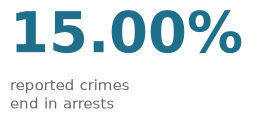

In [100]:
#KPI 1
fig, ax = plt.subplots(figsize=(3, 1.5))
big_number(ax, f'{percentage_arrests:.2f}%', 'reported crimes\nend in arrests')
plt.show()

In [ ]:
#KPI 2: Average crimes per month
year_month = df['Date'].str[6:10] + '-' + df['Date'].str[:2]
year_month = year_month[(year_month >= '2021-01') & (year_month < '2026-11')]

month_counts = year_month.value_counts()

print(f"{month_counts.mean():,.0f}")

20,109


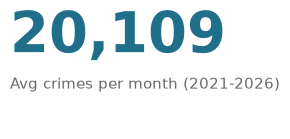

In [132]:
fig, ax = plt.subplots(figsize=(3, 1.5))
big_number(ax, f"{month_counts.mean():,.0f}", "Avg crimes per month (2021-2026)")
plt.show()